In [1]:
import sys; sys.path.append("..")
from db import engine
import pandas as pd
pd.read_sql("SELECT DB_NAME() AS db", engine)

,db
0,CapacityPlanning


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("..") / "data"
INCOMING = DATA / "incoming"
DATA.mkdir(exist_ok=True)
INCOMING.mkdir(exist_ok=True)

rng = np.random.default_rng(42)
HISTORY_WEEKS = 104
FUTURE_WEEKS = 8
TOTAL_WEEKS = HISTORY_WEEKS + FUTURE_WEEKS
START = pd.Timestamp("2024-10-21")
print("Setup done. Data will be saved in:", DATA.resolve())

Matplotlib is building the font cache; this may take a moment.


Setup done. Data will be saved in: C:\Projects\capacity-ledger-bi\data


In [3]:
REQUEST_TYPES = {
    "patient": {"team": "Patient Requests",  "base": 3000, "minutes": {"digital": 8,  "fax": 15, "mail": 18}},
    "legal":   {"team": "Legal & Insurance", "base": 1200, "minutes": {"digital": 18, "fax": 28, "mail": 32}},
    "insurer": {"team": "Legal & Insurance", "base": 900,  "minutes": {"digital": 14, "fax": 22, "mail": 26}},
    "payer":   {"team": "Payer Requests",    "base": 2500, "minutes": {"digital": 6,  "fax": 12, "mail": 14}},
}
PAID_HOURS = 37.5
SHRINKAGE = 0.22
ATTRITION_MONTHLY = 0.02
HIRE_LAG_WEEKS = 4
PRODUCTIVE_HOURS = PAID_HOURS * (1 - SHRINKAGE)
print("Productive hours per FTE per week:", PRODUCTIVE_HOURS)

Productive hours per FTE per week: 29.25


In [4]:
rows = []
t = np.arange(TOTAL_WEEKS)
for rtype, info in REQUEST_TYPES.items():
    trend = 1 + 0.10 * t / 52
    season = 1 + 0.08 * np.sin(2 * np.pi * (t + 8) / 52)
    noise = rng.normal(1, 0.04, TOTAL_WEEKS)
    total = info["base"] * trend * season * noise
    digital_share = np.clip(0.35 + 0.25 * t / (HISTORY_WEEKS - 1) + rng.normal(0, 0.015, TOTAL_WEEKS), 0, 0.85)
    for i in range(TOTAL_WEEKS):
        week_start = (START + pd.Timedelta(weeks=i)).date()
        digital = total[i] * digital_share[i]
        paper = total[i] - digital
        rows.append([week_start, rtype, "digital", round(digital)])
        rows.append([week_start, rtype, "fax", round(paper * 0.7)])
        rows.append([week_start, rtype, "mail", round(paper * 0.3)])
all_requests = pd.DataFrame(rows, columns=["week_start", "request_type", "channel", "volume"])
all_requests.head(6)

,week_start,request_type,channel,volume
0,2024-10-21,patient,digital,1104
1,2024-10-21,patient,fax,1493
2,2024-10-21,patient,mail,640
3,2024-10-28,patient,digital,1020
4,2024-10-28,patient,fax,1445
5,2024-10-28,patient,mail,619


In [5]:
handle_time = pd.DataFrame(
    [[rtype, ch, info["team"], mins] for rtype, info in REQUEST_TYPES.items() for ch, mins in info["minutes"].items()],
    columns=["request_type", "channel", "team", "minutes"])
handle_time

,request_type,channel,team,minutes
0,patient,digital,Patient Requests,8
1,patient,fax,Patient Requests,15
2,patient,mail,Patient Requests,18
3,legal,digital,Legal & Insurance,18
4,legal,fax,Legal & Insurance,28
5,legal,mail,Legal & Insurance,32
6,insurer,digital,Legal & Insurance,14
7,insurer,fax,Legal & Insurance,22
8,insurer,mail,Legal & Insurance,26
9,payer,digital,Payer Requests,6


In [6]:
history_cutoff = (START + pd.Timedelta(weeks=HISTORY_WEEKS)).date()
requests = all_requests[all_requests["week_start"] < history_cutoff]
future = all_requests[all_requests["week_start"] >= history_cutoff]

work = requests.merge(handle_time, on=["request_type", "channel"])
work["hours"] = work["volume"] * work["minutes"] / 60
team_hours = work.groupby(["team", "week_start"])["hours"].sum()
team_hours.groupby("team").mean().round(0)

team
Legal & Insurance    835.0
Patient Requests     665.0
Payer Requests       433.0
Name: hours, dtype: float64

In [7]:
weekly_attrition = 1 - (1 - ATTRITION_MONTHLY) ** (12 / 52)
agents = []
next_id = 1
for team in sorted(handle_time["team"].unique()):
    hours = team_hours.loc[team].values
    start_headcount = int(np.ceil(hours[:4].mean() / PRODUCTIVE_HOURS * 1.05))
    team_agents = []
    for _ in range(start_headcount):
        tenure_weeks = int(rng.integers(20, 300))
        fte = 0.5 if rng.random() < 0.1 else 1.0
        team_agents.append({"agent_id": f"A{next_id:04d}", "team": team,
                            "start_date": START - pd.Timedelta(weeks=tenure_weeks), "end_date": None, "fte": fte})
        next_id += 1
    for w in range(HISTORY_WEEKS):
        week = START + pd.Timedelta(weeks=w)
        for a in team_agents:
            if a["end_date"] is None and a["start_date"] <= week and rng.random() < weekly_attrition:
                a["end_date"] = week
        if w % 4 == 0:
            active = sum(a["fte"] for a in team_agents if a["end_date"] is None and a["start_date"] <= week)
            pending = sum(a["fte"] for a in team_agents if a["start_date"] > week)
            needed = hours[max(0, w - 3): w + 1].mean() / PRODUCTIVE_HOURS * 1.11
            for _ in range(max(0, int(np.floor(needed - active - pending)))):
                team_agents.append({"agent_id": f"A{next_id:04d}", "team": team,
                                    "start_date": week + pd.Timedelta(weeks=HIRE_LAG_WEEKS), "end_date": None, "fte": 1.0})
                next_id += 1
    agents += team_agents

roster = pd.DataFrame(agents)
last_week = START + pd.Timedelta(weeks=HISTORY_WEEKS - 1)
roster = roster[roster["start_date"] <= last_week].copy()
roster["start_date"] = roster["start_date"].dt.date
roster["end_date"] = pd.to_datetime(roster["end_date"]).dt.date
print("Agents in roster:", len(roster), "| still employed:", roster["end_date"].isna().sum())
roster.head()

Agents in roster: 113 | still employed: 71


,agent_id,team,start_date,end_date,fte
0,A0001,Legal & Insurance,2022-06-06,2026-05-04,1.0
1,A0002,Legal & Insurance,2021-04-19,NaT,1.0
2,A0003,Legal & Insurance,2019-11-18,NaT,1.0
3,A0004,Legal & Insurance,2022-06-13,NaT,1.0
4,A0005,Legal & Insurance,2024-04-08,NaT,1.0


In [8]:
hires = roster[roster["start_date"] >= START.date()][["start_date", "agent_id", "team"]].rename(columns={"start_date": "event_date"})
hires["event"] = "hire"
exits = roster.dropna(subset=["end_date"])[["end_date", "agent_id", "team"]].rename(columns={"end_date": "event_date"})
exits["event"] = "exit"
golive = pd.DataFrame([{"event_date": (START + pd.Timedelta(weeks=HISTORY_WEEKS + 5)).date(), "agent_id": "",
                        "team": "All", "event": "client_golive"}])
events = pd.concat([hires, exits, golive]).sort_values("event_date")
events["event"].value_counts()

event
exit             42
hire             37
client_golive     1
Name: count, dtype: int64

In [9]:
assumptions = pd.DataFrame([
    ["paid_hours_per_week", 37.5, 37.5, 37.5, "HR", "Employment policy"],
    ["shrinkage", 0.22, 0.18, 0.26, "WFM / HR", "Attendance and training records"],
    ["attrition_monthly", 0.02, 0.015, 0.03, "HR", "Trailing 12-month exits"],
    ["hourly_cost", 30, 26, 34, "Finance", "Placeholder loaded labor rate"],
    ["overtime_premium", 1.5, 1.5, 1.5, "Finance", "Overtime policy"],
    ["ramp_weeks_1_4", 0.25, 0.20, 0.35, "Training", "New-hire cohort results"],
    ["ramp_weeks_5_8", 0.50, 0.40, 0.60, "Training", "New-hire cohort results"],
    ["ramp_weeks_9_12", 0.75, 0.65, 0.85, "Training", "New-hire cohort results"],
    ["time_to_hire_weeks", 4, 3, 8, "Talent Acquisition", "Requisition history"],
], columns=["name", "value", "low", "high", "owner", "source"])
assumptions["review_date"] = "2027-01-15"
assumptions

,name,value,low,high,owner,source,review_date
0,paid_hours_per_week,37.50,37.500,37.50,HR,Employment policy,2027-01-15
1,shrinkage,0.22,0.180,0.26,WFM / HR,Attendance and training records,2027-01-15
2,attrition_monthly,0.02,0.015,0.03,HR,Trailing 12-month exits,2027-01-15
3,hourly_cost,30.00,26.000,34.00,Finance,Placeholder loaded labor rate,2027-01-15
4,overtime_premium,1.50,1.500,1.50,Finance,Overtime policy,2027-01-15
5,ramp_weeks_1_4,0.25,0.200,0.35,Training,New-hire cohort results,2027-01-15
6,ramp_weeks_5_8,0.50,0.400,0.60,Training,New-hire cohort results,2027-01-15
7,ramp_weeks_9_12,0.75,0.650,0.85,Training,New-hire cohort results,2027-01-15
8,time_to_hire_weeks,4.00,3.000,8.00,Talent Acquisition,Requisition history,2027-01-15


In [10]:
requests.to_csv(DATA / "requests.csv", index=False)
handle_time.to_csv(DATA / "handle_time.csv", index=False)
roster.to_csv(DATA / "roster.csv", index=False)
events.to_csv(DATA / "events.csv", index=False)
assumptions.to_csv(DATA / "assumptions.csv", index=False)
for week_start, week_rows in future.groupby("week_start"):
    week_rows.to_csv(INCOMING / f"requests_{week_start}.csv", index=False)
print("History files:", sorted(p.name for p in DATA.glob("*.csv")))
print("Incoming files:", sorted(p.name for p in INCOMING.glob("*.csv")))

History files: ['assumptions.csv', 'events.csv', 'handle_time.csv', 'requests.csv', 'roster.csv']
Incoming files: ['requests_2026-10-19.csv', 'requests_2026-10-26.csv', 'requests_2026-11-02.csv', 'requests_2026-11-09.csv', 'requests_2026-11-16.csv', 'requests_2026-11-23.csv', 'requests_2026-11-30.csv', 'requests_2026-12-07.csv']


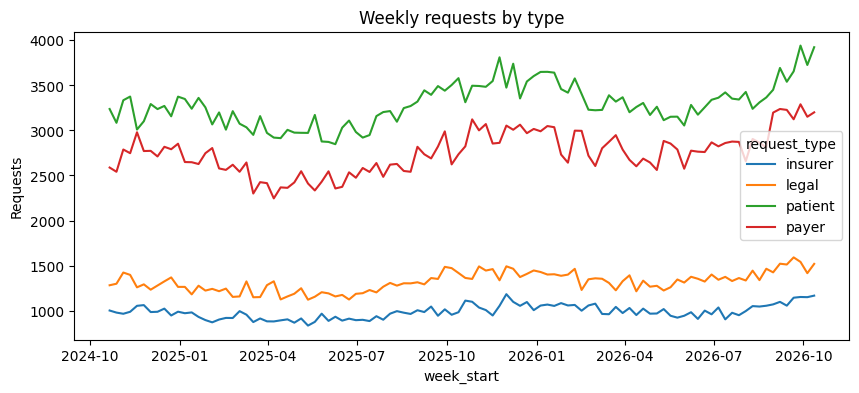

In [11]:
weekly = requests.groupby(["week_start", "request_type"])["volume"].sum().unstack()
weekly.plot(figsize=(10, 4), title="Weekly requests by type")
plt.ylabel("Requests"); plt.show()

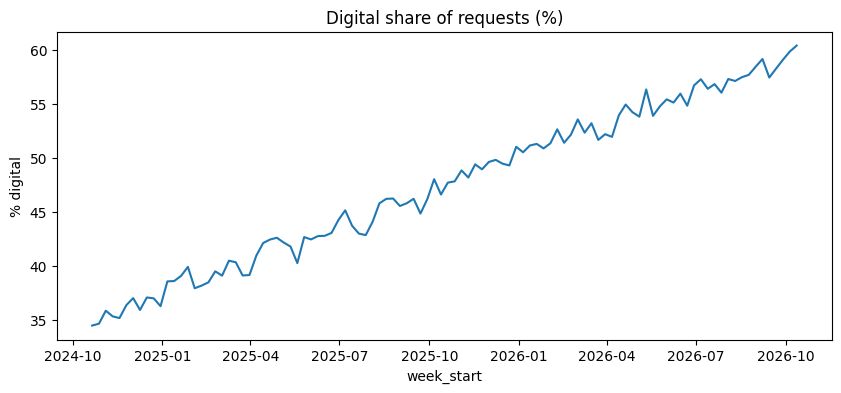

In [12]:
by_channel = requests.groupby(["week_start", "channel"])["volume"].sum().unstack()
digital_share = by_channel["digital"] / by_channel.sum(axis=1) * 100
digital_share.plot(figsize=(10, 4), title="Digital share of requests (%)")
plt.ylabel("% digital"); plt.show()

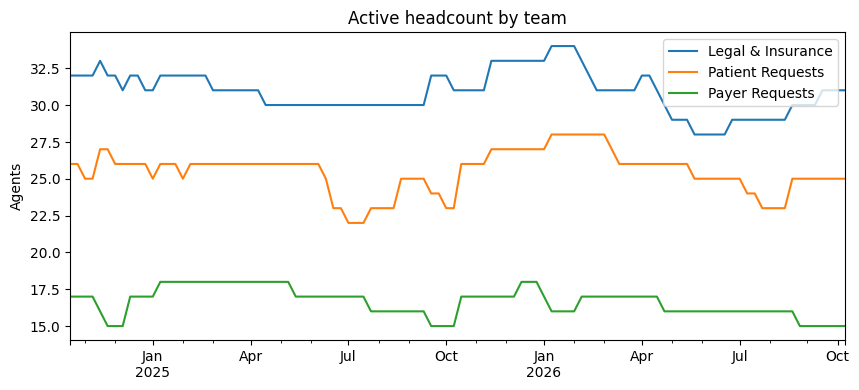

In [13]:
weeks = pd.date_range(START, periods=HISTORY_WEEKS, freq="W-MON")
r = roster.copy()
r["start_date"] = pd.to_datetime(r["start_date"]); r["end_date"] = pd.to_datetime(r["end_date"])
headcount = pd.DataFrame({team: [((g["start_date"] <= w) & (g["end_date"].isna() | (g["end_date"] > w))).sum() for w in weeks]
                          for team, g in r.groupby("team")}, index=weeks)
headcount.plot(figsize=(10, 4), title="Active headcount by team")
plt.ylabel("Agents"); plt.show()